# Labels: what counts as a fire start

**What this answers:** How a fire start (onset) and a matched non-fire day are defined, and how many of each there are.

**What it reads:** The label rules in `configs/domain.yaml`, the cell-day table, the season file and the modelling table.

**What to expect:** A rule table, one worked example, the seasons per state, and onset counts per year.

Load the reporting helpers.

In [1]:
from wildfire.reporting import labels
from IPython.display import display

**The rules.** Every setting comes from the configuration file, not from this notebook.

In [2]:
display(labels.rule_table())

,rule,setting
0,grid cell,"5000 m square, projection EPSG:6933"
1,forest domain,tree fraction >= 0.2
2,onset,a detection with none in the 3 days before
3,negatives,20 per onset: random cell-day in the domain an...
4,season,months holding 90% of a state's onsets up to 2023
5,predictors,observed 1 day(s) before the target day or ear...


**A worked example.** Consecutive detection days of one busy cell. Only the first day of a run is an onset.

In [3]:
display(labels.onset_example())

,cell,day,n,onset
0,51517,17897,42,True
1,51517,17898,61,False
2,51517,17899,46,False
3,51517,17900,60,False
4,51517,17901,54,False
5,51517,17902,47,False
6,51517,17903,55,False
7,51517,17904,51,False
8,51517,17905,48,False
9,51517,17906,64,False


**Fire season per state.** Non-fire days are drawn only inside these months.

In [4]:
display(labels.season_table())

,state,months
0,AP,"1, 2, 3, 4"
1,CG,"2, 3, 4, 5, 12"
2,JH,"1, 2, 3, 4, 5, 6, 12"
3,KA,"1, 2, 3, 12"
4,KL,"1, 2, 12"
5,MH,"1, 2, 3, 4, 5, 12"
6,MP,"1, 2, 3, 4, 5, 11"
7,OD,"1, 2, 3, 4, 5, 12"
8,TN,"1, 2, 4, 12"
9,TS,"1, 2, 3, 4, 5, 12"


**Onsets per year.** Each onset comes with 20 matched days without a fire.

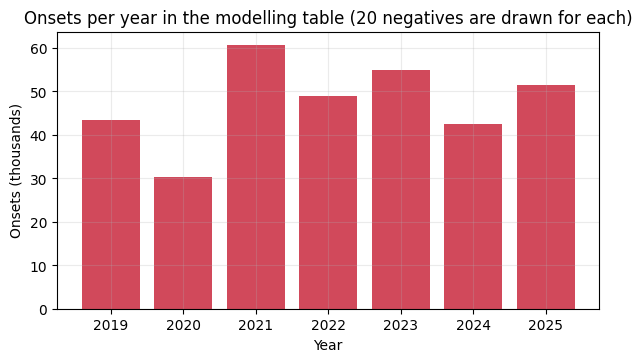

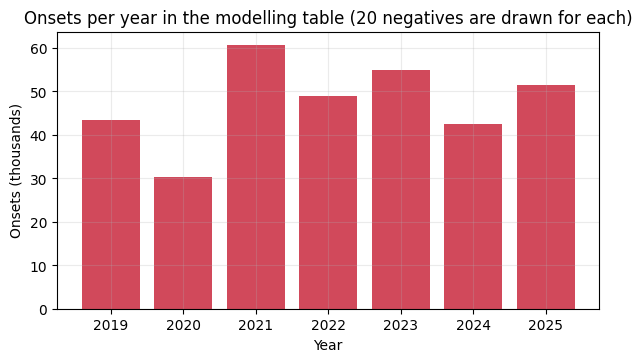

In [5]:
labels.plot_rows_by_year()

**One cell.** The unit of the study is a 5 km x 5 km grid cell (25 km2). This is the training cell with the most onsets, drawn to scale with the cells around it. Neighbours that are not in the forest domain are hatched.

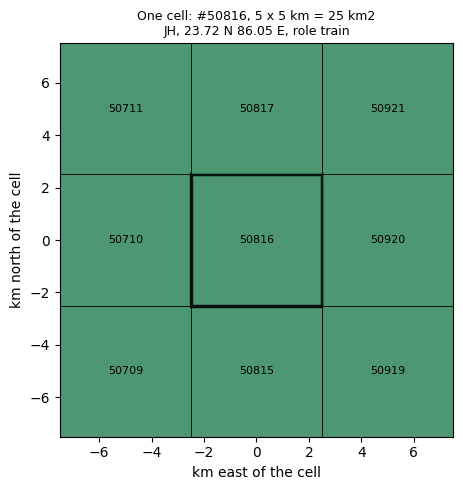

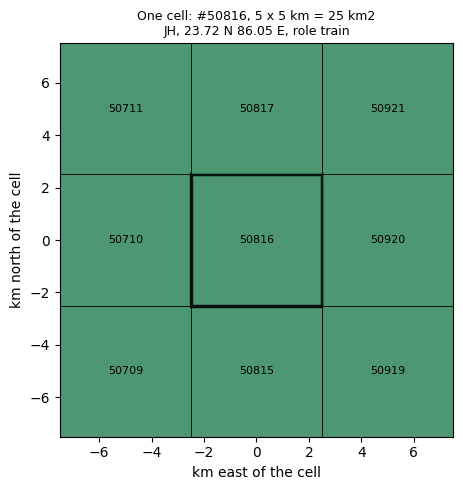

In [6]:
labels.plot_cell_block()

**One cell over days.** The same cell in its busiest year. Bars are detections per day (red on an onset). Every marker on the bottom line is one row: this cell on one day, with label 1 on an onset and label 0 on a matched day without a fire.

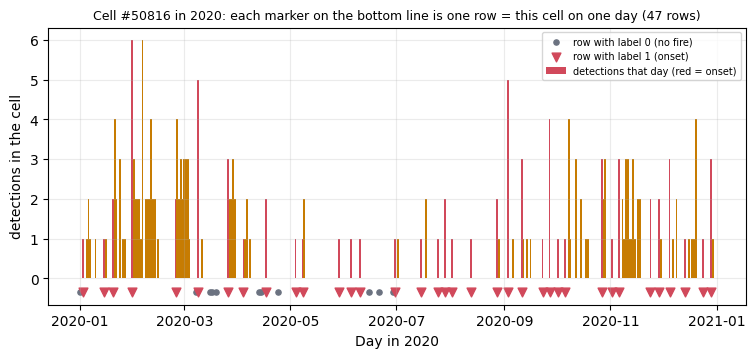

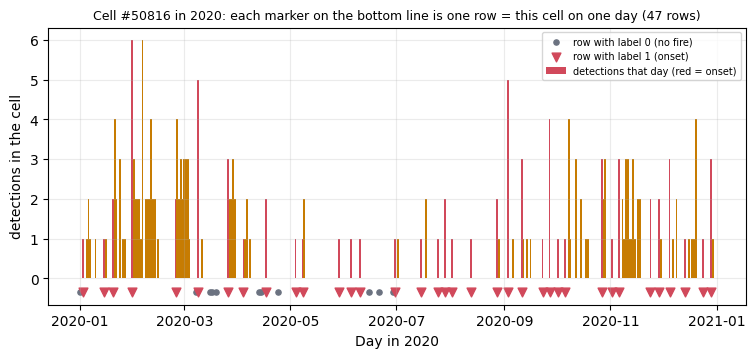

In [7]:
labels.plot_cell_days()

**One row per cell and day.** The first rows of that cell. A row is a cell on a single day; the models predict one such row at a time.

In [8]:
display(labels.cell_rows_table())

,cell,date,label,kind,state,detections,frp_mw
0,50816,2020-01-01,0,negative,JH,0,NaN
1,50816,2020-01-03,1,onset,JH,1,0.87
2,50816,2020-01-15,1,onset,JH,1,0.71
3,50816,2020-01-20,1,onset,JH,2,9.65
4,50816,2020-01-31,1,onset,JH,6,18.37
5,50816,2020-02-25,1,onset,JH,2,6.52
6,50816,2020-03-08,0,negative,JH,0,NaN
7,50816,2020-03-09,1,onset,JH,5,11.79
8,50816,2020-03-16,0,negative,JH,0,NaN
9,50816,2020-03-17,0,negative,JH,0,NaN


**From cell-days to rows.** Almost all possible cell-days are not rows: a cell-day is kept only if it is an onset or was drawn as one of the 20 matched non-fire days. The counts are for the main forest band up to 2025-07-31, the rows the models are built from; about 0.5% of them are dropped later for missing inputs.

In [9]:
display(labels.row_counts_table())

,quantity,value
0,training cells with rows (5 x 5 km each),"17,764"
1,days in the label window,"2,404"
2,possible cell-days,"42,704,656"
3,labelled rows kept (main forest band),"6,900,100"
4,onsets (label 1),"332,891"
5,matched non-fire days (label 0),"6,567,209"
6,rows per cell: median,373
7,rows per cell: largest,685


## What this shows

An onset is the first detection after the configured number of quiet days. Matched negatives come from the same state, year and season. The plot shows how many onsets each year contributes. The cell views show that one row is one 5 km cell on one day, and how few of all possible cell-days become rows.

## What it does not show

It does not show that every fire is labelled (satellites miss small or cloud-covered fires), and it says nothing about fire causes.